In [2]:
import os
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Hiragino Sans'  # macOS標準日本語フォント

import importlib
# それぞれのモジュールをインポート
import data_utils
import preprocess
import feature_extraction

# 修正を反映
importlib.reload(data_utils)
importlib.reload(preprocess)
importlib.reload(feature_extraction)

# 必要な関数やクラスを再度ノートブックに取り込む
from data_utils import *
from preprocess import *
from feature_extraction import *

In [3]:
# 定数
LABEL_COUNT = 18 # ラベル数
SAMPLING_RATE = 70  # サンプリングレート

data_folder = "../data/20250809"

file_paths = [f for f in os.listdir(data_folder) if f.endswith('.txt')]

for i in range(len(file_paths)):
    print(f"{i:2}:{file_paths[i]}")

# row_data = []
# row_csi = []

# row_amp = []    # 振幅
# row_phase = []  # 位相

# # 前処理
# buttter_filtered__csi = []
# median_filtered_csi = []

# # 分割
# split_data = []
# split_csi = []
# merged_split_data = []  # [ラベル][分割後データ数][データ]
# merged_split_csi = []   # [ラベル][分割後データ数][CSI]

# # クラス数を削減
# restored_split_csi = []

 0:20250809_161644_data.txt
 1:20250809_161047_data.txt
 2:20250809_162821_data.txt
 3:20250809_162443_data.txt
 4:20250809_160455_data.txt
 5:20250809_160802_data.txt
 6:20250809_162150_data.txt
 7:20250809_161336_data.txt
 8:20250809_161904_data.txt
 9:20250809_160221_data.txt


In [4]:
# row_data/row_csiにデータを格納する
row_data, row_csi = load_csi_data(LABEL_COUNT, data_folder, file_paths)

# 振幅と位相を分割
row_amp, row_phase = split_amp_phase(row_csi)

In [5]:
# row_dataから常に0のサブキャリアを削除する
row_amp, orig_subcarriers_num, new_subcarriers_num= remove_zero_subcarriers(row_amp)

print(f"元のサブキャリア数: {orig_subcarriers_num}")
print(f"削除後のサブキャリア数: {new_subcarriers_num}")

元のサブキャリア数: 192
削除後のサブキャリア数: 166


In [6]:
# 500msごとに分割（各ファイルの先頭msを基準に相対時間で分割）
split_data, split_csi = split_by_interval(row_data, row_amp, interval_ms=500)

# 各ラベルごとに全ファイルの分割データを連結する
merged_split_data, merged_split_csi = merge_split_data(split_data, split_csi)

In [7]:
# クラスの削減

# 使いたいラベルのインデックス
target_labels = [[0, 1], [3], [5, 6],
                 [21, 22], [24], [26, 27]]

target_labels = [[0, 1, 7, 8, 14, 15, 21, 22, 28, 29, 35, 36], 
                 [2, 3, 4, 9, 10, 11, 16, 17, 18, 23, 24, 25, 30, 31, 32, 37, 38, 39],
                 [5, 6, 12, 13, 19, 20, 26, 27, 33, 34, 40, 41]]

target_labels = [[0, 1], [3], [5, 6],
                 [21, 22], [24], [26, 27]]

target_labels = [[0], [1], [2], [9], [10], [11]]


# クラス削減（ラベルグループ化）を関数で実行
restored_split_csi = group_labels_by_indices(merged_split_csi, target_labels)

print(len(restored_split_csi[0]))
print(len(row_csi[0]))

135
10


Class 0


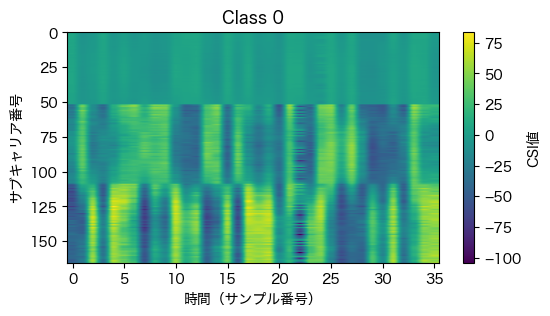

Class 1


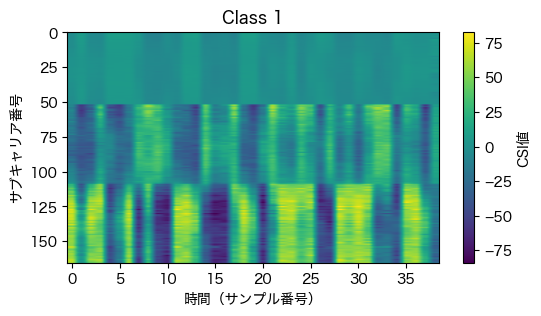

Class 2


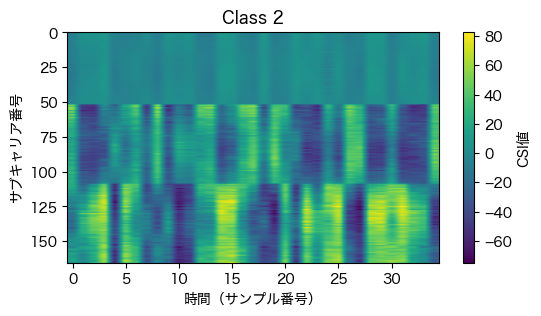

Class 3


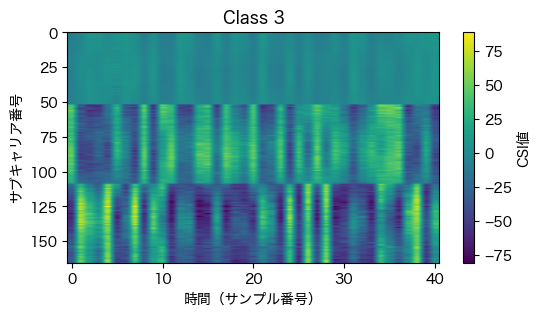

Class 4


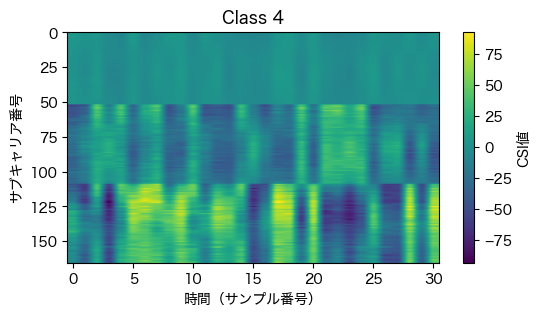

Class 5


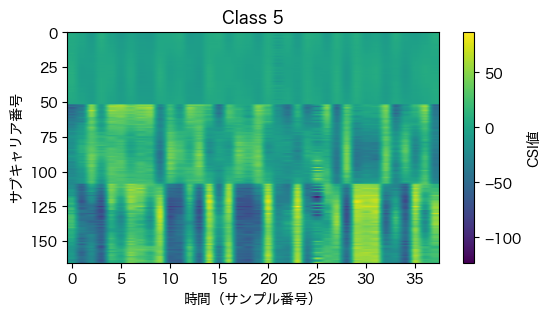

In [8]:
import numpy as np
import matplotlib.pyplot as plt

def csi_heatmap(csi_segment, title=None):
    """
    CSI分割データ（[時間][サブキャリア]）をヒートマップ表示
    """
    csi_array = np.array(csi_segment)  # [時間][サブキャリア]
    plt.figure(figsize=(6, 3))
    plt.imshow(csi_array.T, aspect='auto', cmap='viridis')
    plt.xlabel('時間（サンプル番号）')
    plt.ylabel('サブキャリア番号')
    if title:
        plt.title(title)
    plt.colorbar(label='CSI値')
    plt.show()

# 例：6分類の各クラスの最初の1サンプルを表示
for class_idx, class_csi in enumerate(restored_split_csi):
    if len(class_csi) > 0:
        print(f"Class {class_idx}")
        csi_heatmap(class_csi[1], title=f"Class {class_idx}")

Class 0
Class 1
Class 2
Class 3
Class 4
Class 5


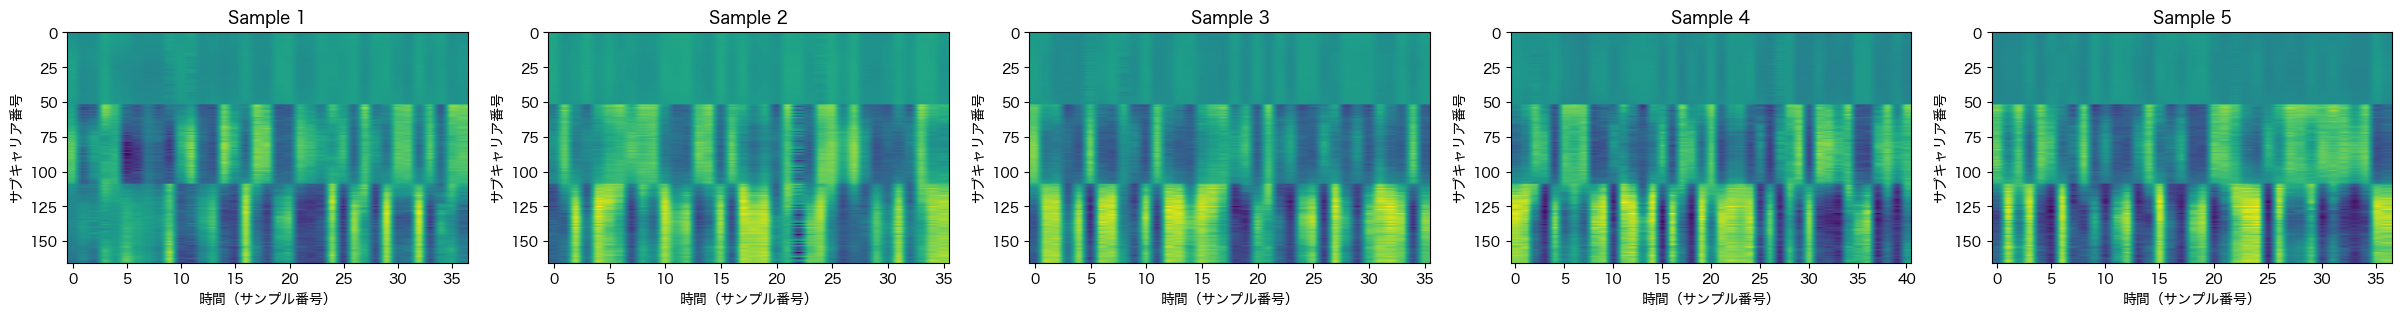

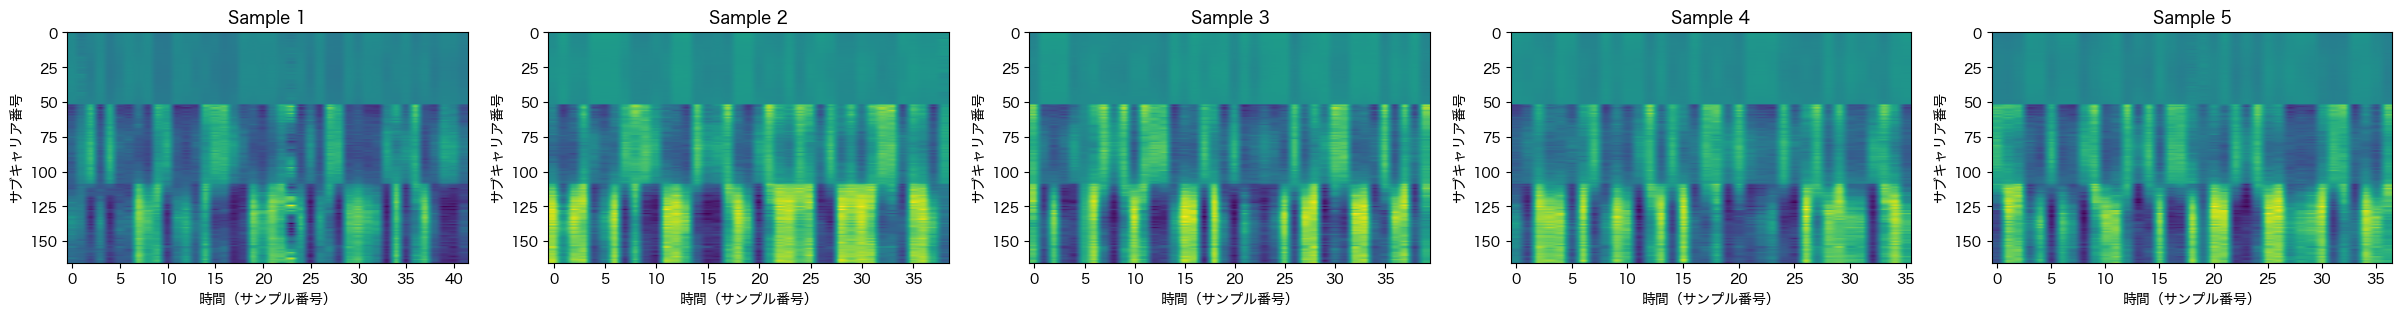

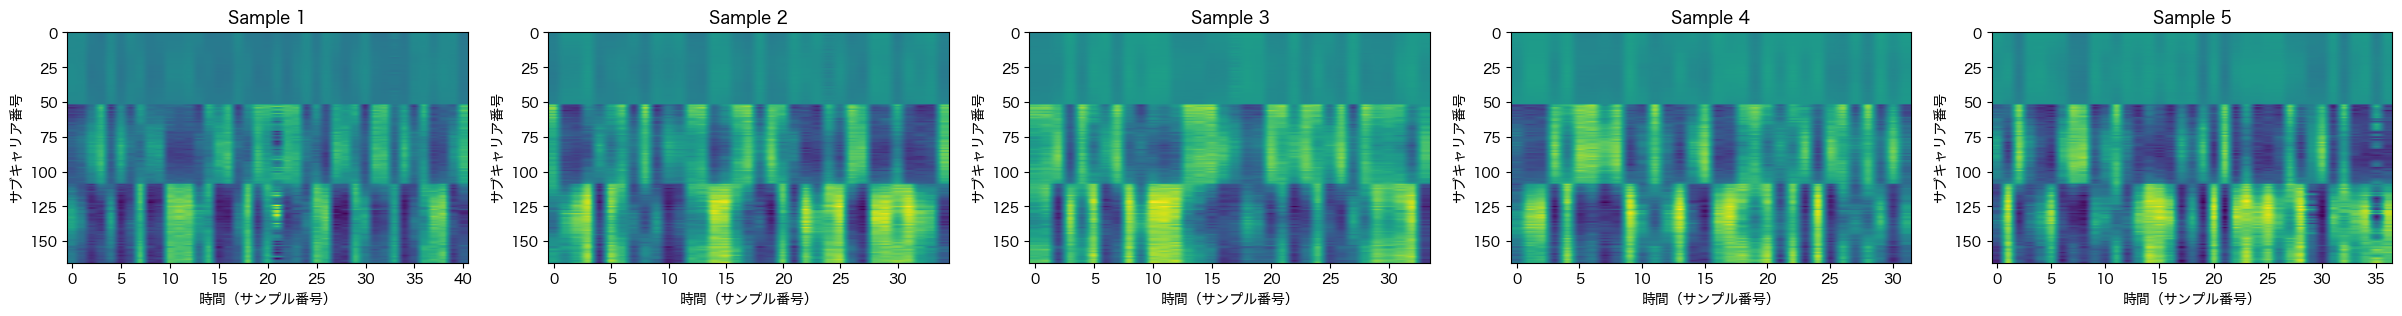

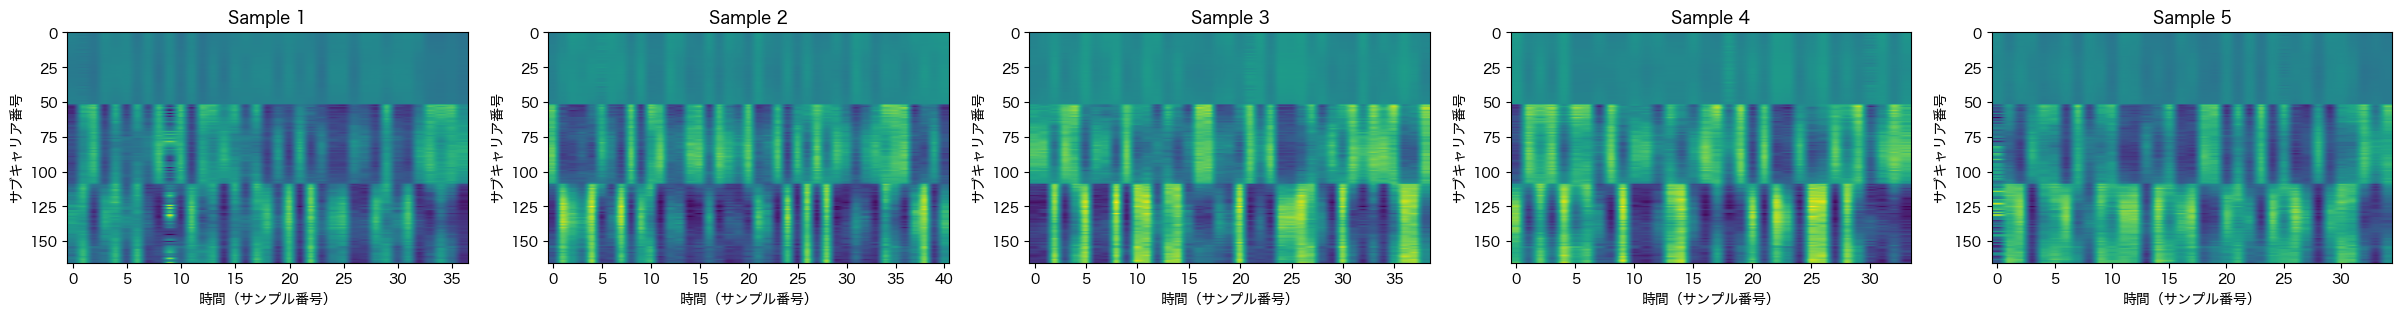

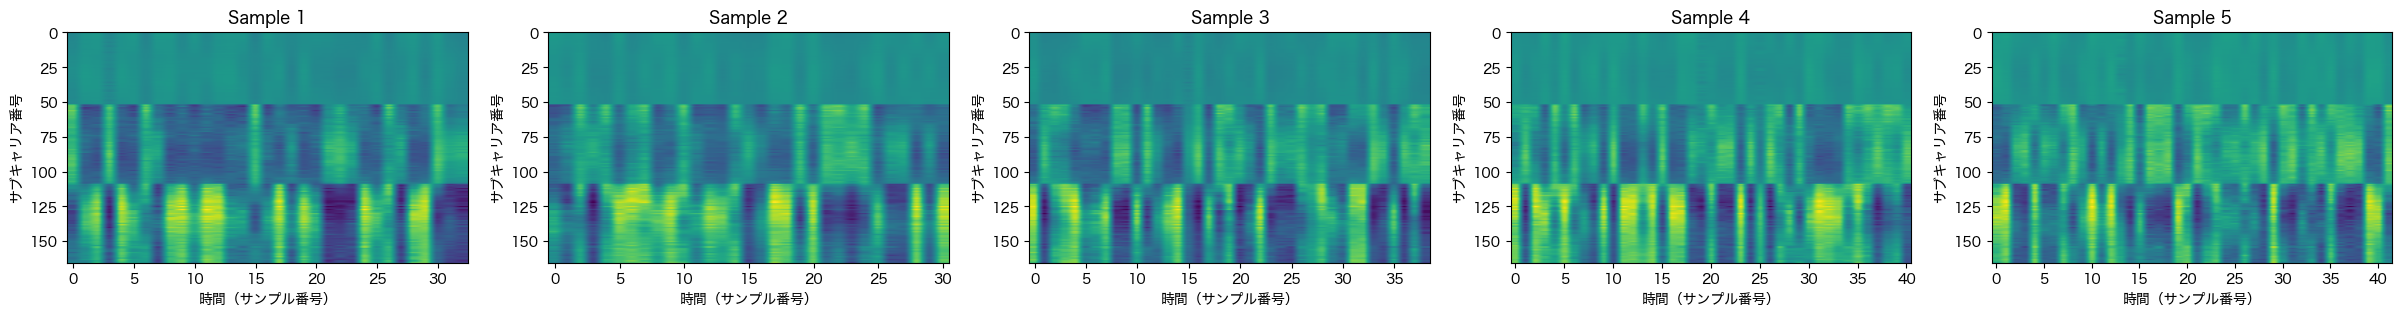

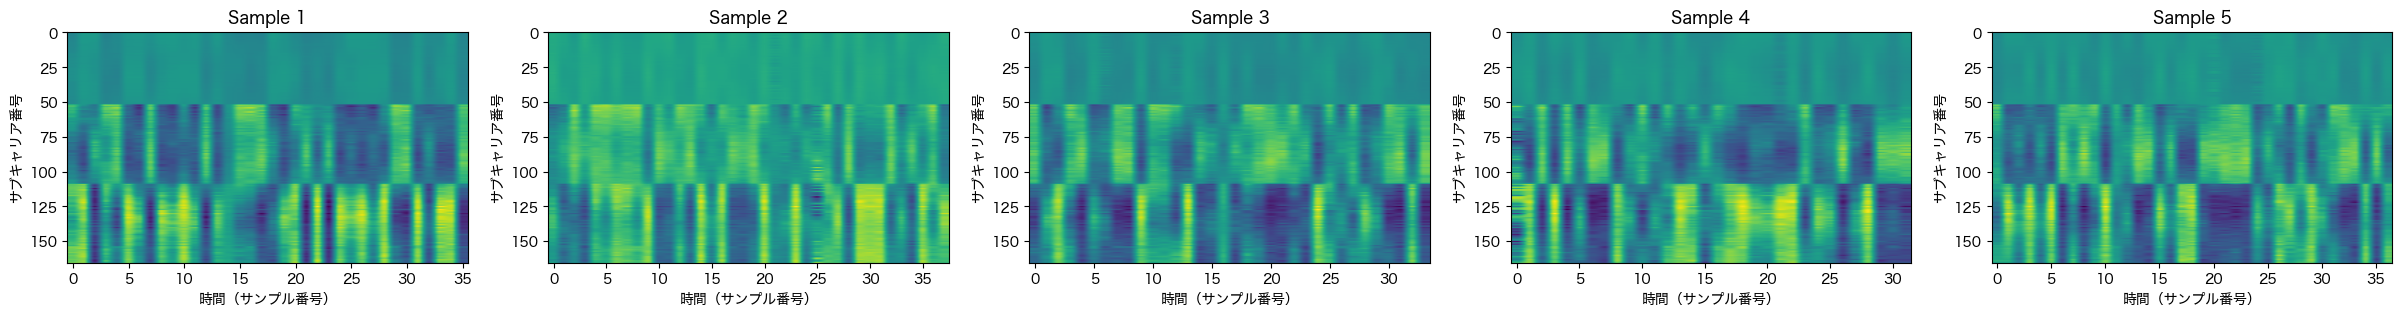

In [9]:
# 各クラスの最初の5サンプルを横に並べてヒートマップ表示
for class_idx, class_csi in enumerate(restored_split_csi):
    print(f"Class {class_idx}")
    sample_count = min(5, len(class_csi))
    fig, axes = plt.subplots(1, sample_count, figsize=(6 * sample_count, 3))
    if sample_count == 1:
        axes = [axes]
    for i in range(sample_count):
        csi_array = np.array(class_csi[i])
        axes[i].imshow(csi_array.T, aspect='auto', cmap='viridis')
        axes[i].set_title(f"Sample {i+1}")
        axes[i].set_xlabel('時間（サンプル番号）')
        axes[i].set_ylabel('サブキャリア番号')

In [10]:
# --- セル1: データ分割などの前処理 ---
from sklearn.model_selection import train_test_split
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

# 全サンプルの最小時間長を取得
min_time_length = min(
    [np.array(sample).shape[0] for class_csi in restored_split_csi for sample in class_csi]
)
print(f"全サンプルの最小時間長: {min_time_length}")

# データセット作成（トリミングして揃える）
class CSIDataset(Dataset):
    def __init__(self, restored_split_csi, min_time_length):
        self.images = []
        self.labels = []
        for class_idx, class_csi in enumerate(restored_split_csi):
            for sample in class_csi:
                arr = np.array(sample)[:min_time_length, :]  # 時間長をトリミング
                arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)  # 正規化
                arr = arr.T  # [サブキャリア, 時間]
                arr = np.expand_dims(arr, axis=0)  # [1, サブキャリア, 時間]
                self.images.append(arr.astype(np.float32))
                self.labels.append(class_idx)
        self.images = np.stack(self.images)
        self.labels = np.array(self.labels)

dataset = CSIDataset(restored_split_csi, min_time_length)
images = dataset.images
labels = dataset.labels

# 2:8で分割（20%テスト, 80%トレーニング）
X_train, X_test, y_train, y_test = train_test_split(
    images, labels, test_size=0.2, random_state=42, stratify=labels
)

class NumpyCSIDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        return self.images[idx], self.labels[idx]

train_dataset = NumpyCSIDataset(X_train, y_train)
test_dataset = NumpyCSIDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

全サンプルの最小時間長: 21


In [11]:
# --- セル2: CNNモデル定義と学習 ---
import torch.nn as nn
import torch.optim as optim

class SimpleCNN(nn.Module):
    def __init__(self, num_classes, in_height, in_width):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        # プーリング2回後のサイズ
        h = in_height // 4
        w = in_width // 4
        self.fc1 = nn.Linear(32 * h * w, 128)
        self.fc2 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.pool(x)
        x = self.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# deviceの定義
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 入力画像サイズを取得
_, in_height, in_width = images.shape[1:]
model = SimpleCNN(num_classes=6, in_height=in_height, in_width=in_width).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 学習ループ
for epoch in range(5):
    model.train()
    running_loss = 0.0
    for inputs, labels in train_loader:
        inputs = torch.tensor(inputs).to(device)
        labels = torch.tensor(labels).to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader):.4f}")

/var/folders/1t/t4kcdkfn739d7sm39jwk28zh0000gn/T/ipykernel_91357/3298596375.py:43: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  inputs = torch.tensor(inputs).to(device)
/var/folders/1t/t4kcdkfn739d7sm39jwk28zh0000gn/T/ipykernel_91357/3298596375.py:44: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)


Epoch 1, Loss: 1.8048
Epoch 2, Loss: 1.7914
Epoch 3, Loss: 1.7848
Epoch 4, Loss: 1.7610
Epoch 5, Loss: 1.7295


In [12]:
# --- セル3: 評価 ---
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = torch.tensor(inputs).to(device)
        labels = torch.tensor(labels).to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f"Test Accuracy: {100 * correct / total:.2f}%")

Test Accuracy: 28.75%


/var/folders/1t/t4kcdkfn739d7sm39jwk28zh0000gn/T/ipykernel_91357/4101106039.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  inputs = torch.tensor(inputs).to(device)
/var/folders/1t/t4kcdkfn739d7sm39jwk28zh0000gn/T/ipykernel_91357/4101106039.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  labels = torch.tensor(labels).to(device)
